# Bài 3 – Gender CNN

Châu Quốc Bảo – 3123411024. Dùng core của TV1. Xem `data/README_DATA.md` về nguồn, định dạng và giới hạn so sánh. EarlyStopping khôi phục mô hình tốt nhất theo validation loss; ReduceLROnPlateau theo dõi cùng đại lượng. Baseline dùng epoch cuối.

Nếu CSV và checkpoint đã tồn tại, notebook hiển thị kết quả đã chạy. Đặt `RETRAIN = True` để huấn luyện lại.


In [1]:
from pathlib import Path
import os
if Path.cwd().name == 'notebooks':
    os.chdir('..')
from src.face_experiment import run, plot_comparison, demo_gender


In [2]:
DATA = Path('data/UTKFace')
EPOCHS, BATCH_SIZE, SEED = 30, 128, 42
RETRAIN = False
assert DATA.exists(), 'Hãy chuẩn bị dữ liệu theo data/README_DATA.md'


In [3]:
import csv
result_path = Path('logs/result_03_gender_baseline.csv')
checkpoint_path = Path('checkpoints/03_gender_baseline.pt')
if RETRAIN or not result_path.exists() or not checkpoint_path.exists():
    baseline = run('gender', DATA, 'baseline', epochs=EPOCHS, batch_size=BATCH_SIZE, seed=SEED)
else:
    with result_path.open(encoding="utf-8", newline="") as f:
        baseline = next(csv.DictReader(f))
baseline


{'task': 'gender',
 'variant': 'baseline',
 'train_count': '18963',
 'val_count': '2370',
 'test_count': '2372',
 'seed': '42',
 'epochs_run': '30',
 'batch_size': '128',
 'initial_lr': '0.001',
 'optimizer': 'Adam',
 'parameters': '5270562',
 'test_loss': '0.6629790439573549',
 'test_accuracy': '0.8849072512647554',
 'keras_reference_loss': '0.4602',
 'keras_reference_accuracy': '0.8264',
 'seconds': '303.1868336200714',
 'device': 'cuda',
 'torch_version': '2.6.0+cu124'}

In [4]:
import csv
result_path = Path('logs/result_03_gender_callbacks.csv')
checkpoint_path = Path('checkpoints/03_gender_callbacks.pt')
if RETRAIN or not result_path.exists() or not checkpoint_path.exists():
    improved = run('gender', DATA, 'callbacks', epochs=EPOCHS, batch_size=BATCH_SIZE, seed=SEED)
else:
    with result_path.open(encoding="utf-8", newline="") as f:
        improved = next(csv.DictReader(f))
improved


{'task': 'gender',
 'variant': 'callbacks',
 'train_count': '18963',
 'val_count': '2370',
 'test_count': '2372',
 'seed': '42',
 'epochs_run': '13',
 'batch_size': '128',
 'initial_lr': '0.001',
 'optimizer': 'Adam',
 'parameters': '5270562',
 'test_loss': '0.2487686850369278',
 'test_accuracy': '0.8933389544688027',
 'keras_reference_loss': '0.3237',
 'keras_reference_accuracy': '0.8773',
 'seconds': '131.4493613243103',
 'device': 'cuda',
 'torch_version': '2.6.0+cu124'}

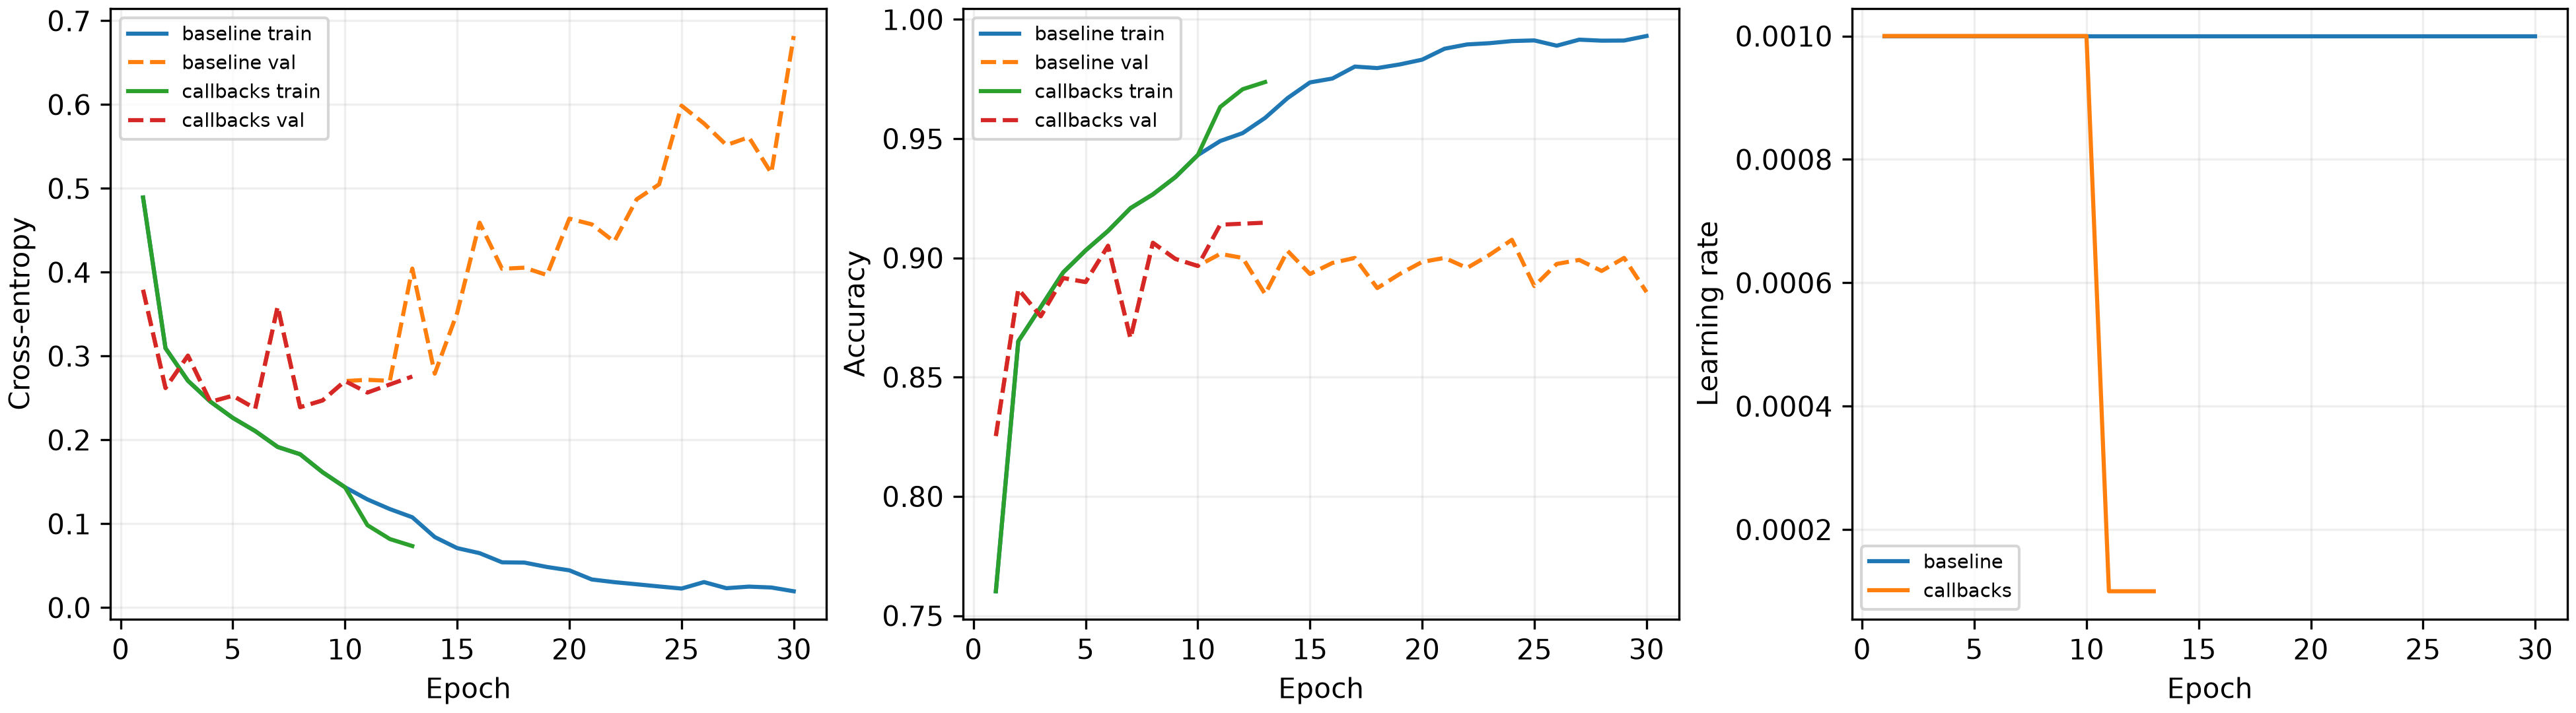

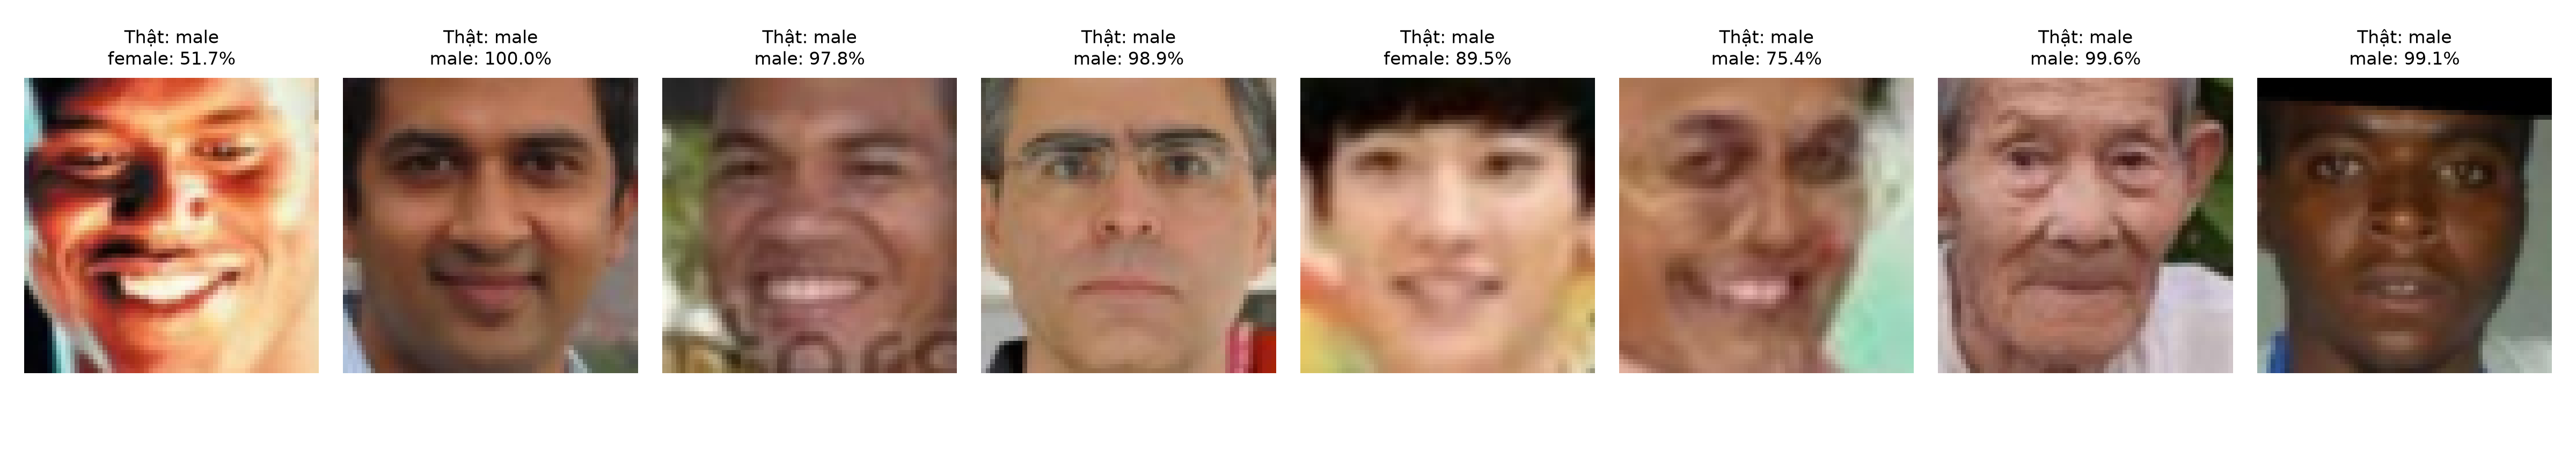

In [5]:
plot_comparison('gender')
demo_gender(DATA, seed=SEED)
from IPython.display import display, Image
display(Image(filename='figures/03_gender_before_after_callbacks.png'))
display(Image(filename='figures/03_gender_demo_predictions.png'))


So sánh các tệp `logs/result_*` và đường cong. Mốc Keras trong slide chỉ để tham khảo; chỉ kết luận về hiệu quả kỹ thuật khi có kết quả chạy thực tế.
